# 03. LSTM으로 과거 12개에서 다음 값 1개 예측하기
기본필수 `03_lstm.py`의 실제 실행 결과를 바탕으로 **시간순 분할 → window 생성 → 입력 특성 축 추가 → LSTM → 마지막 은닉 출력 → 다음 값 예측**을 확인합니다.

이 실습은 학습 전 모델의 순전파를 확인합니다. 정답과 예측의 차이를 관찰하되, 모델의 학습 성능이나 검증 성능으로 해석하지 않습니다.

## 0. 작업 전 준비사항
PyTorch, pandas, matplotlib이 설치된 커널에서 **Run All**로 실행합니다. CPU와 기존 `series.csv`를 사용하며 다운로드는 필요하지 않습니다. 원본 Python 파일을 수정하지 않고 실행해 변수와 결과를 읽습니다. 표와 그림은 `20261103/01_기본필수/docs/outputs`에 저장합니다.

In [1]:
%matplotlib inline
from pathlib import Path
import runpy
import torch
from torch import nn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
day_root = next((candidate for parent in (cwd, *cwd.parents)
                 for candidate in (parent / "20261103", parent)
                 if (candidate / "01_기본필수" / "03_lstm.py").is_file()), None)
if day_root is None:
    raise FileNotFoundError("이 저장소 안에서 실행하세요.")
out = day_root / "01_기본필수" / "docs" / "outputs"
out.mkdir(parents=True, exist_ok=True)
state = runpy.run_path(str(day_root / "01_기본필수" / "03_lstm.py"))
df, train, valid, window, x, y, lstm, head, output, h_n, c_n, prediction = (
    state[name] for name in ["df", "train", "valid", "window", "x", "y", "lstm", "head", "output", "h_n", "c_n", "prediction"])
B = x.size(0)

입력 / 정답: (48, 12, 1) (48, 1)
h_n / c_n: (1, 48, 8) (1, 48, 8)
예측: (48, 1)
첫 예측: 0.014645
학습 전 MSE: 0.374487


## 1. 시간순 분할을 먼저 하는 이유
CSV의 시간순 행을 유지하며 split 열에 따라 train 60개, valid 20개를 분리합니다. test 20개는 모델에 전달하지 않습니다. 이번 파일은 train으로만 window를 만들고, valid는 읽어두지만 예측·평가에 사용하지 않습니다.

전체 관측에서 window를 만든 뒤 무작위로 나누면 인접 window가 공유하는 관측이 train과 valid에 섞일 수 있습니다. 따라서 **원래 시간 구간을 나누고, 각 구간 안에서만 window를 생성**합니다. 이번 train window끼리 관측을 공유하는 것은 학습 구간 내부의 중첩이며 train·valid 경계 중첩과 구분합니다.

In [2]:
print("분할별 원관측 수:", df.groupby("split", sort=False).size().to_dict())
assert train.shape == (60,)
assert valid.shape == (20,)
assert window.shape == (48, 13)
print("train:", tuple(train.shape), "/ valid:", tuple(valid.shape))

분할별 원관측 수: {'train': 60, 'valid': 20, 'test': 20}
train: (60,) / valid: (20,)


## 2. unfold로 과거 12개와 정답 1개 묶기
```python
window = train.unfold(0, 13, 1)
```

| 인자 | 값 | 의미 |
| --- | --- | --- |
| dimension | 0 | 1차원 관측 텐서의 시간 축 |
| size | 13 | 과거 12개와 다음 정답 1개를 포함한 길이 |
| step | 1 | window 시작점을 한 시점씩 이동 |

관측 60개에서 window 수는 `(60 - 13) // 1 + 1 = 48`개입니다. 첫 행은 `train[0:13]`, 다음 행은 `train[1:14]`이며 마지막 행은 `train[47:60]`입니다. 인접 window는 12개 관측을 공유합니다. `unfold()`는 원본 저장 공간을 공유하는 뷰를 반환하므로 제자리 수정은 피합니다.

첫 window의 앞 12개 `train[0:12]`가 입력이고, 그 다음 값 `train[12]`가 정답입니다. 정답은 해당 입력에 포함되지 않습니다. 한 시점의 관측이 이전 window에서는 정답, 다음 window에서는 과거 입력이 될 수 있는데 이는 관측이 순차적으로 주어지는 one-step 구성입니다.

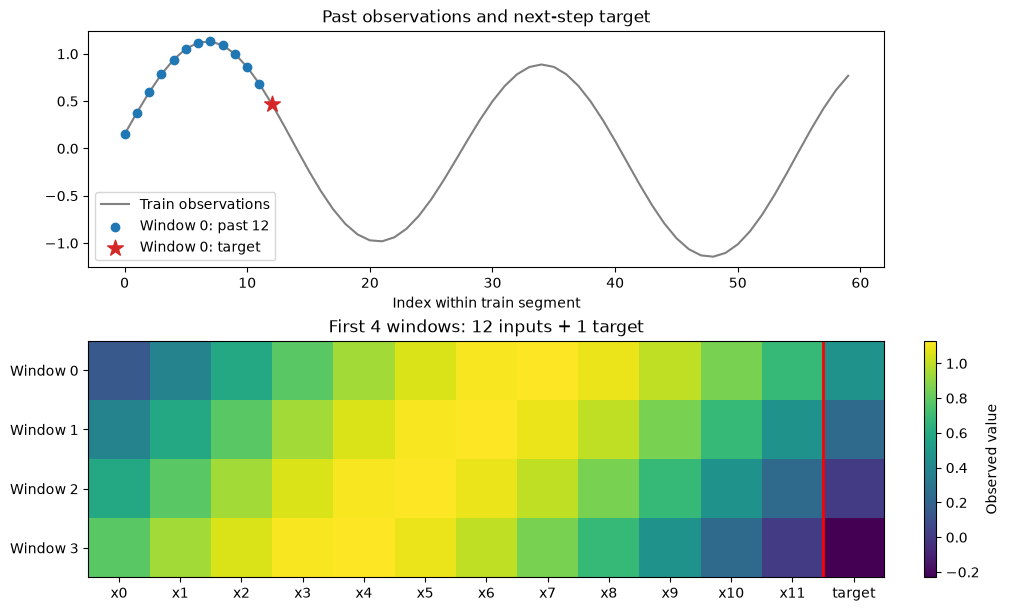

In [3]:
assert torch.equal(window[0], train[:13])
assert torch.equal(window[1], train[1:14])
assert torch.equal(window[-1], train[47:60])
fig, axes = plt.subplots(2, 1, figsize=(10, 6), constrained_layout=True)
axes[0].plot(range(60), train.numpy(), color="grey", label="Train observations")
axes[0].scatter(range(12), train[:12].numpy(), color="tab:blue", label="Window 0: past 12", zorder=3)
axes[0].scatter([12], [train[12].item()], color="tab:red", marker="*", s=140, label="Window 0: target", zorder=4)
axes[0].set_xlabel("Index within train segment")
axes[0].legend()
axes[0].set_title("Past observations and next-step target")
im = axes[1].imshow(window[:4].numpy(), aspect="auto", cmap="viridis")
axes[1].axvline(11.5, color="red", linewidth=2)
axes[1].set_xticks(range(13), [f"x{i}" for i in range(12)] + ["target"])
axes[1].set_yticks(range(4), [f"Window {i}" for i in range(4)])
axes[1].set_title("First 4 windows: 12 inputs + 1 target")
fig.colorbar(im, ax=axes[1], label="Observed value")
fig.savefig(out / "lstm_windows.png", dpi=140)
plt.show()
plt.close(fig)

## 3. unsqueeze는 특성 축 추가
```python
x = window[:, :12].unsqueeze(-1)
y = window[:, 12:13]
```

`window[:, :12]`로 각 window의 입력 12개를 선택하면 `(48,12)`입니다. `unsqueeze(-1)`은 마지막에 크기 1인 축을 추가하여 **(B,T,F)=(48,12,1)**로 만듭니다. 값이나 원소 수는 바뀌지 않으며 이 파일에는 Padding이 없습니다.

한 시점의 입력 특성은 관측값 하나이므로 F=1입니다. `batch_first=True`인 LSTM은 배치·시점·특성 순서의 입력을 받습니다. y의 `12:13` 슬라이스는 축을 유지해 `(48,1)`이 되며, `window[:,12]`처럼 정수 인덱스를 쓰면 `(48,)`이 됩니다.

In [4]:
assert x.shape == (48, 12, 1)
assert y.shape == (48, 1)
assert torch.equal(x.squeeze(-1), window[:,:12])
assert torch.equal(y[:,0], window[:,12])
print("특성 축 추가 전:", tuple(window[:,:12].shape))
print("특성 축 추가 후:", tuple(x.shape))
print("정답:", tuple(y.shape))
first_window = pd.DataFrame({"position": range(13), "value": window[0].numpy(),
                            "role": ["past_input"]*12+["next_target"]})
print(first_window.to_string(index=False))
first_window.to_csv(out / "lstm_first_window.csv", index=False)

특성 축 추가 전: (48, 12)
특성 축 추가 후: (48, 12, 1)
정답: (48, 1)
 position    value        role
        0 0.150000  past_input
        1 0.377600  past_input
        2 0.592438  past_input
        3 0.783147  past_input
        4 0.939593  past_input
        5 1.053411  past_input
        6 1.118447  past_input
        7 1.131084  past_input
        8 1.090430  past_input
        9 0.998368  past_input
       10 0.859460  past_input
       11 0.680704  past_input
       12 0.471171 next_target


## 4. LSTM의 output·h_n·c_n
```python
lstm = nn.LSTM(1, 8, batch_first=True)
output, (h_n, c_n) = lstm(x)
```

input_size=1은 시점별 입력 특성 수, hidden_size=8은 은닉 특성 수입니다. 기본값은 1층·단방향이며 초기 h0·c0를 생략하면 0에서 시작합니다.

| 텐서 | 이번 shape | 의미 |
| --- | --- | --- |
| x | `(48,12,1)` | 과거 12시점의 관측값 |
| output | `(48,12,8)` | 마지막 층의 모든 시점 은닉 출력 |
| h_n | `(1,48,8)` | 각 층·방향의 최종 은닉 상태 |
| c_n | `(1,48,8)` | 각 층·방향의 최종 셀 상태 |

h는 외부 출력과 예측에 쓰이는 은닉 상태이고 c는 게이트를 통해 정보를 유지·갱신하는 셀 상태입니다. 역할이 달라 같은 값이라고 가정하면 안 됩니다. batch_first는 h_n·c_n의 축 순서를 바꾸지 않으며, 첫 축은 `층 수 × 방향 수`입니다.

이번처럼 길이가 모두 12이고 단방향이면 `output[:,-1,:]`와 `h_n[-1]`이 같습니다. 가변 길이 Padding이나 양방향 모델에서는 마지막 실제 시점과 방향을 고려해야 합니다.

마지막 output과 h_n[-1] 일치: True
첫 자료 h: [-0.04873799905180931, 0.1932583451271057, -0.3968304395675659, 0.05382903665304184, -0.06218862533569336, -0.06933626532554626, 0.007164172362536192, -0.01874685473740101]
첫 자료 c: [-0.1568821370601654, 0.44691264629364014, -0.7133676409721375, 0.11547479778528214, -0.13110587000846863, -0.12103494256734848, 0.013150671496987343, -0.036726098507642746]


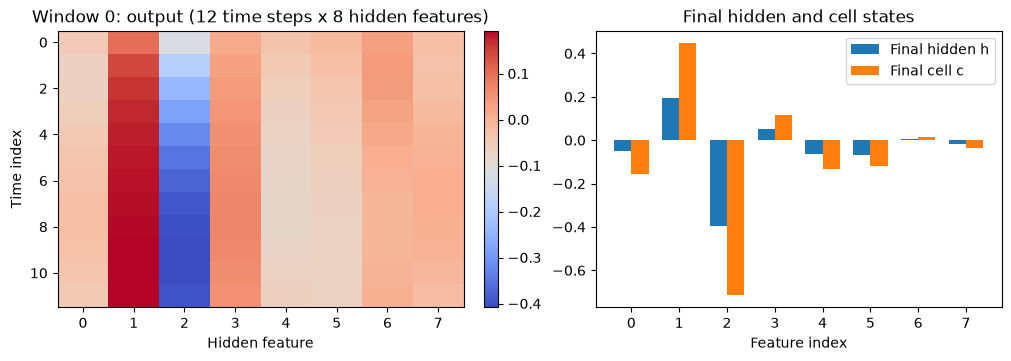

In [5]:
assert output.shape == (B,12,8)
assert h_n.shape == c_n.shape == (1,B,8)
assert torch.allclose(output[:,-1,:], h_n[-1])
print("마지막 output과 h_n[-1] 일치:", torch.allclose(output[:,-1,:], h_n[-1]))
print("첫 자료 h:", h_n[-1,0].detach().tolist())
print("첫 자료 c:", c_n[-1,0].detach().tolist())
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
im = axes[0].imshow(output[0].detach().numpy(), cmap="coolwarm", aspect="auto")
axes[0].set_title("Window 0: output (12 time steps x 8 hidden features)")
axes[0].set_xlabel("Hidden feature")
axes[0].set_ylabel("Time index")
fig.colorbar(im, ax=axes[0])
indices = np.arange(8)
axes[1].bar(indices-.18, h_n[-1,0].detach().numpy(), width=.36, label="Final hidden h")
axes[1].bar(indices+.18, c_n[-1,0].detach().numpy(), width=.36, label="Final cell c")
axes[1].set_xticks(indices)
axes[1].set_xlabel("Feature index")
axes[1].set_title("Final hidden and cell states")
axes[1].legend()
fig.savefig(out / "lstm_hidden_cell.png", dpi=140)
plt.show()
plt.close(fig)

## 5. 마지막 은닉 출력으로 다음 값 예측하기
TODO B03은 마지막 시점의 은닉 특성 8개를 Linear(8,1)에 전달합니다.

```python
head = nn.Linear(8, 1)
prediction = head(output[:, -1, :])
```

`output[:, -1, :]`는 모든 자료에서 마지막 시점만 선택해 `(48,8)`을 만들고, head는 `(48,1)`의 연속값을 출력합니다. 입력의 마지막 관측값을 직접 복사하는 코드가 아니며, 분류 logits나 Softmax 확률도 아닙니다.

MSE는 `(prediction - y)²`의 평균입니다. prediction과 y는 모두 `(48,1)`로 맞춰야 합니다. y가 `(48,)`이면 잘못된 브로드캐스팅으로 `(48,48)` 비교가 될 수 있으므로 shape를 먼저 확인합니다.

이 파일에는 backward나 optimizer.step이 없습니다. 따라서 아래 예측과 MSE는 초기 가중치로 계산한 **train window의 학습 전 값**이며, 낮은 오차가 실습 완료 조건은 아닙니다.

첫 예측: 0.014645
첫 정답: 0.471171
학습 전 MSE: 0.374487
    tensor       shape
    window    (48, 13)
         x (48, 12, 1)
         y     (48, 1)
    output (48, 12, 8)
       h_n  (1, 48, 8)
       c_n  (1, 48, 8)
prediction     (48, 1)


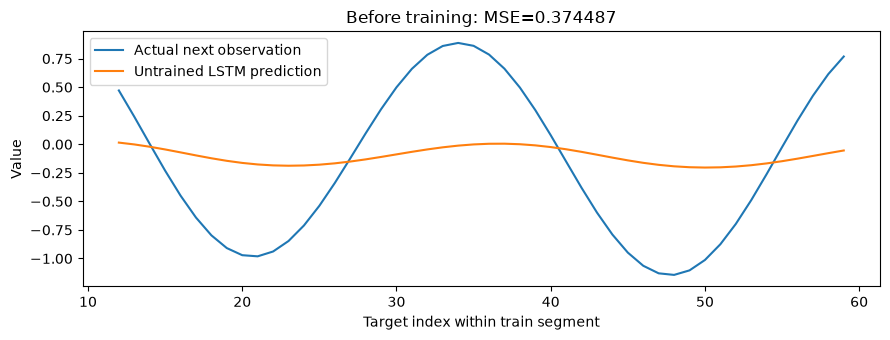

In [6]:
with torch.no_grad():
    checked = head(output[:,-1,:])
assert prediction.shape == y.shape == (48,1)
assert torch.allclose(prediction, checked)
mse = nn.MSELoss()(prediction,y).item()
assert np.isclose(mse, ((prediction-y)**2).mean().item())
print("첫 예측:", round(prediction[0].item(),6))
print("첫 정답:", round(y[0].item(),6))
print("학습 전 MSE:", round(mse,6))
records = pd.DataFrame({"window": range(B), "target_train_index": np.arange(B)+12,
                        "actual": y[:,0].detach().numpy(), "prediction": prediction[:,0].detach().numpy(),
                        "squared_error": ((prediction-y)**2)[:,0].detach().numpy()})
records.to_csv(out / "lstm_untrained_predictions.csv", index=False)
shapes = pd.DataFrame({"tensor": ["window","x","y","output","h_n","c_n","prediction"],
                      "shape": [str(tuple(t.shape)) for t in [window,x,y,output,h_n,c_n,prediction]]})
print(shapes.to_string(index=False))
shapes.to_csv(out / "lstm_shape_flow.csv", index=False)
fig, ax = plt.subplots(figsize=(9,3.5))
ax.plot(records["target_train_index"], records["actual"], label="Actual next observation")
ax.plot(records["target_train_index"], records["prediction"], label="Untrained LSTM prediction")
ax.set_xlabel("Target index within train segment")
ax.set_ylabel("Value")
ax.set_title(f"Before training: MSE={mse:.6f}")
ax.legend()
fig.tight_layout()
fig.savefig(out / "lstm_untrained_predictions.png", dpi=140)
plt.show()
plt.close(fig)

## 6. 결과 해석 및 추가 실험
기본 실행에서 첫 예측은 약 `0.014645`, train window의 학습 전 MSE는 약 `0.374487`입니다. 초기 모델의 예측이 정답 곡선을 잘 따르지 않더라도 아직 학습하지 않았으므로 이상한 결과가 아닙니다.

요구사항에 따라 과거 12개와 다음 정답 1개를 분리하고, 마지막 은닉 출력으로 예측을 계산했습니다. 정답은 해당 window의 입력에 포함되지 않습니다. h와 c는 모두 `(1,48,8)`이지만 역할이 다르고, 이번 예측층은 h에 해당하는 마지막 output만 사용합니다.

### 직접 확인해 볼 내용
- `head(h_n[-1])`과 현재 prediction이 같은지 확인합니다.
- 과거 길이를 6으로 바꾸려면 window 길이·입력 슬라이스·정답 위치를 함께 변경합니다.
- valid를 평가할 때는 valid 구간 안에서 별도로 window를 만들고 train 경계를 넘지 않도록 합니다.
- 모델을 실제 학습시키는 실험은 순전파 실습과 구분하여 기록합니다.

### 자주 하는 실수 점검
- 입력에 해당 window의 다음 정답이 섞이지 않았는가?
- h_n과 c_n의 첫 축을 배치 축이라고 생각하지 않았는가?
- prediction과 y의 shape가 같은가?
- 학습 전 train MSE를 학습 후 valid 성능으로 해석하지 않았는가?